# Telecom Customer Churn Prediction — Ensemble ML

This notebook trains and compares **Random Forest** and **XGBoost** models for telecom customer churn. It includes categorical preprocessing with `OneHotEncoder`, class balancing with **SMOTE**, cross-validation, ROC-AUC evaluation, confusion matrices, and the top 10 feature importances.

> The notebook calculates metrics when you run it. An ROC-AUC above 0.80 is a target, not a guaranteed result; performance depends on the data split and model settings.

## 1. Install dependencies

The next cell installs any missing packages into the **same Python environment the notebook kernel uses**. Alternatively, run `python -m pip install -r requirements.txt` in a terminal and restart the kernel.

In [1]:
import importlib.util, subprocess, sys

REQUIRED = {                      # import name -> pip package name
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "sklearn": "scikit-learn", "imblearn": "imbalanced-learn", "xgboost": "xgboost",
}
missing = [pip_name for mod, pip_name in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
    print("Installed. If the next cell still raises ImportError, restart the kernel and run all cells again.")
else:
    print("All dependencies are already installed.")

All dependencies are already installed.


In [2]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier

RANDOM_STATE = 42

DATA_NAME = "Telco-Customer-Churn.csv"
DATA_URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
            "master/data/Telco-Customer-Churn.csv")

def locate_dataset():
    """Look next to the notebook, in ./data, and one level up; then search below the cwd."""
    for folder in (Path.cwd(), Path.cwd() / "data", Path.cwd().parent, Path.cwd().parent / "data"):
        if (folder / DATA_NAME).exists():
            return folder / DATA_NAME
    return next(iter(Path.cwd().rglob(DATA_NAME)), None)

DATA_PATH = locate_dataset()

if DATA_PATH is None:  # last resort: try to download the public IBM sample copy
    try:
        import urllib.request
        urllib.request.urlretrieve(DATA_URL, DATA_NAME)
        DATA_PATH = Path(DATA_NAME)
        print("Downloaded dataset from", DATA_URL)
    except Exception as exc:
        raise FileNotFoundError(
            f"{DATA_NAME} not found under {Path.cwd()} and automatic download failed ({exc}). "
            f"Download it manually and place it in {Path.cwd()}."
        ) from exc

print("Dataset path:", DATA_PATH.resolve())
print("Imports and dataset path configured successfully!")

Dataset path: D:\Datheon_Machine_Learning_-_Data_Science_Internship\telecom_churn_ensemble_project\Telco-Customer-Churn.csv
Imports and dataset path configured successfully!


## 2. Load and inspect the dataset

In [3]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
display(df["Churn"].value_counts(dropna=False).rename("count").to_frame())
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("missing values"))

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,count
Churn,
No,5174
Yes,1869


,missing values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


## 3. Clean data and define features

In [4]:
# TotalCharges is stored as text in the common Telco dataset. Blank strings become NaN.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna(subset=["Churn"]).copy()

# CustomerID is an identifier, not a useful generalizable predictive feature.
X = df.drop(columns=["Churn", "customerID"], errors="ignore")
y = df["Churn"].map({"No": 0, "Yes": 1})

# Remove any rows with an unmapped target label, if present.
valid = y.notna()
X, y = X.loc[valid].copy(), y.loc[valid].astype(int)
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()

print("Rows:", len(X))
print("Categorical features:", categorical_features)
print("Numeric features:", numeric_features)
print("Churn rate: {:.2%}".format(y.mean()))

Rows: 7043
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Churn rate: 26.54%


## 4. Train/test split and preprocessing

The test set is held out until final evaluation. Numeric columns use median imputation; categorical columns use most-frequent imputation and `OneHotEncoder`. SMOTE is placed **inside the modeling pipeline**, so resampling happens only on each training fold and does not leak synthetic samples into validation/test data.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

try:
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:  # compatibility with older scikit-learn
    onehot = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", SkPipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]), numeric_features),
        ("cat", SkPipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", onehot)
        ]), categorical_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False
)

print("Training rows:", X_train.shape[0], "| Test rows:", X_test.shape[0])

Training rows: 5634 | Test rows: 1409


## 5. Define Random Forest and XGBoost models

In [6]:
# SMOTE is applied after one-hot encoding. It may create fractional values in encoded
# indicator columns; this is a common practical baseline for this workflow.
rf_pipeline = ImbPipeline(steps=[
    ("preprocess", clone(preprocessor)),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=2,
        class_weight=None,  # SMOTE handles imbalance
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

xgb_pipeline = ImbPipeline(steps=[
    ("preprocess", clone(preprocessor)),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.04,
        subsample=0.85,
        colsample_bytree=0.85,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

models = {
    "Random Forest": rf_pipeline,
    "XGBoost": xgb_pipeline
}

## 6. Cross-validation using ROC-AUC

Stratified 5-fold cross-validation evaluates each pipeline on the training split. Preprocessing and SMOTE are refit within each fold.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring={"roc_auc": "roc_auc", "accuracy": "accuracy"},
        n_jobs=1, return_train_score=False
    )
    cv_rows.append({
        "Model": name,
        "CV ROC-AUC mean": scores["test_roc_auc"].mean(),
        "CV ROC-AUC std": scores["test_roc_auc"].std(),
        "CV accuracy mean": scores["test_accuracy"].mean()
    })

cv_results = pd.DataFrame(cv_rows).sort_values("CV ROC-AUC mean", ascending=False)
display(cv_results.style.format({
    "CV ROC-AUC mean": "{:.4f}",
    "CV ROC-AUC std": "{:.4f}",
    "CV accuracy mean": "{:.4f}"
}))

,Model,CV ROC-AUC mean,CV ROC-AUC std,CV accuracy mean
1,XGBoost,0.8432,0.0090,0.8025
0,Random Forest,0.8339,0.0098,0.7916


## 7. Fit models and evaluate on the held-out test set

In [8]:
fitted_models = {}
test_results = []
test_probabilities = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    fitted_models[name] = model
    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)
    auc = roc_auc_score(y_test, probabilities)
    test_probabilities[name] = probabilities
    test_results.append({
        "Model": name,
        "Test ROC-AUC": auc,
        "Test accuracy": (predictions == y_test).mean()
    })
    print(f"\n{name} — ROC-AUC: {auc:.4f}")
    print(classification_report(y_test, predictions, target_names=["No churn", "Churn"], zero_division=0))

test_results = pd.DataFrame(test_results).sort_values("Test ROC-AUC", ascending=False)
display(test_results.style.format({"Test ROC-AUC": "{:.4f}", "Test accuracy": "{:.4f}"}))

best_model_name = test_results.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
best_auc = test_results.iloc[0]["Test ROC-AUC"]
print(f"Best test ROC-AUC: {best_model_name} ({best_auc:.4f})")
print("Target ROC-AUC > 0.80:", "MET" if best_auc > 0.80 else "NOT MET — consider tuning or additional feature work")

Training Random Forest...

Random Forest — ROC-AUC: 0.8309
              precision    recall  f1-score   support

    No churn       0.84      0.87      0.85      1035
       Churn       0.60      0.53      0.56       374

    accuracy                           0.78      1409
   macro avg       0.72      0.70      0.71      1409
weighted avg       0.77      0.78      0.78      1409

Training XGBoost...

XGBoost — ROC-AUC: 0.8413
              precision    recall  f1-score   support

    No churn       0.85      0.88      0.86      1035
       Churn       0.63      0.56      0.59       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



,Model,Test ROC-AUC,Test accuracy
1,XGBoost,0.8413,0.7963
0,Random Forest,0.8309,0.7807


Best test ROC-AUC: XGBoost (0.8413)
Target ROC-AUC > 0.80: MET


## 8. ROC curves

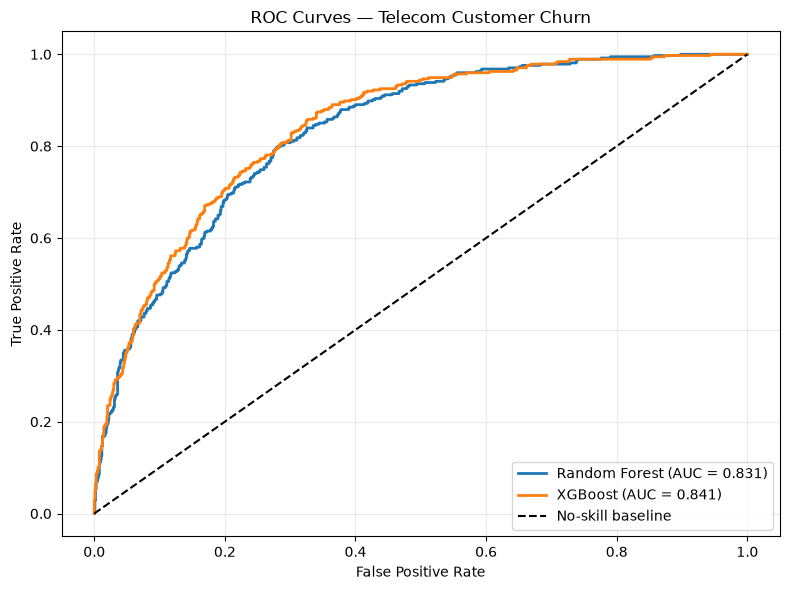

In [9]:
plt.figure(figsize=(8, 6))
for name, probabilities in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    auc = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="No-skill baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Telecom Customer Churn")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Confusion matrices

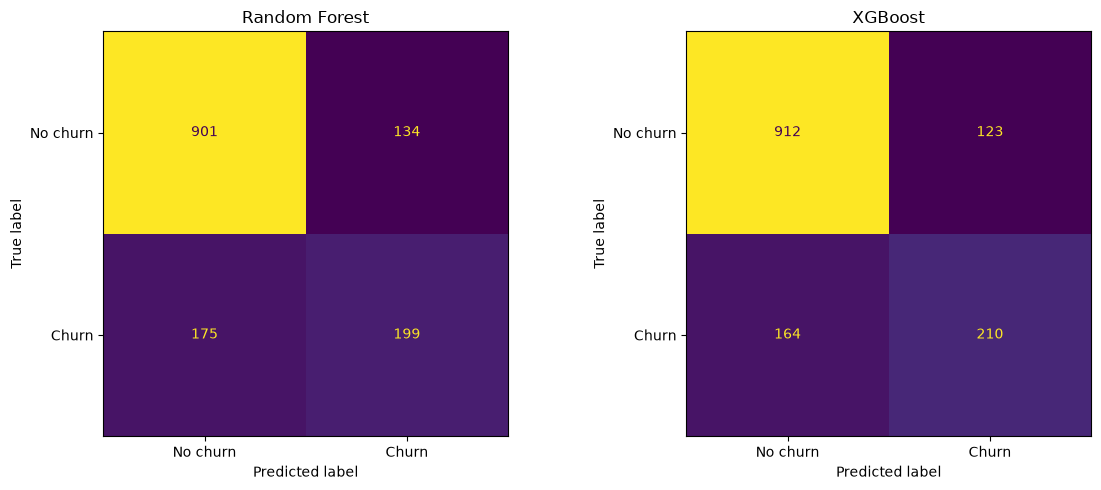

In [10]:
fig, axes = plt.subplots(1, len(fitted_models), figsize=(12, 5))
if len(fitted_models) == 1:
    axes = [axes]
for ax, (name, model) in zip(axes, fitted_models.items()):
    pred = (test_probabilities[name] >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"]).plot(
        ax=ax, colorbar=False, values_format="d"
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 10. Top 10 feature importances

Feature importance is extracted after one-hot encoding. For tree-based models, impurity-based importance can favor some feature types; consider permutation importance or SHAP for a more robust interpretation.

,Feature,Importance
0,Contract_Month-to-month,0.316677
1,OnlineSecurity_No,0.092135
2,TechSupport_No,0.070132
3,PaymentMethod_Electronic check,0.068782
4,OnlineBackup_No,0.043618
5,InternetService_Fiber optic,0.037448
6,PaperlessBilling_Yes,0.022277
7,PaperlessBilling_No,0.021989
8,Dependents_Yes,0.019610
9,Dependents_No,0.018557


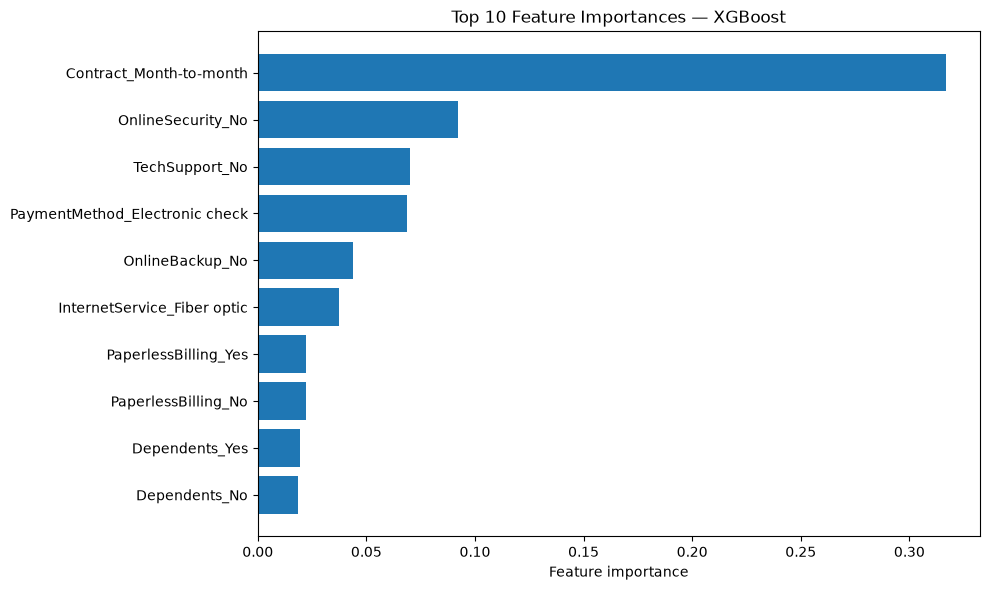

In [11]:
fitted_preprocessor = best_model.named_steps["preprocess"]
tree_model = best_model.named_steps["model"]
feature_names = fitted_preprocessor.get_feature_names_out()
importances = tree_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

top10 = importance_df.head(10).sort_values("Importance", ascending=True)
display(top10.sort_values("Importance", ascending=False).reset_index(drop=True))

plt.figure(figsize=(10, 6))
plt.barh(top10["Feature"], top10["Importance"])
plt.xlabel("Feature importance")
plt.title(f"Top 10 Feature Importances — {best_model_name}")
plt.tight_layout()
plt.show()

## 11. Save evaluation outputs

This cell exports the CV scores, test scores, and top feature importances to CSV files in the project folder.

In [12]:
cv_results.to_csv("cross_validation_results.csv", index=False)
test_results.to_csv("test_metrics.csv", index=False)
importance_df.to_csv("feature_importances.csv", index=False)
print("Saved: cross_validation_results.csv, test_metrics.csv, feature_importances.csv")

Saved: cross_validation_results.csv, test_metrics.csv, feature_importances.csv


## Notes

- The notebook excludes `customerID` because it is a unique identifier.
- `TotalCharges` is converted to numeric; blank or invalid values become missing and are imputed.
- SMOTE is used within each training pipeline to avoid test-set leakage.
- The 0.5 decision threshold is a default. For business use, select a threshold based on the cost of missed churners versus false alarms.
- Do not claim ROC-AUC exceeds 0.80 until the notebook has been run and the actual held-out score confirms it.